In [1]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.preprocessing import StandardScaler
# import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("2020-Apr.csv", nrows=5000000)

In [3]:
df = df.drop(columns = ['event_time', 'user_session'])
df

,event_type,product_id,category_id,category_code,brand,price,user_id
0,view,1201465,2232732101407408685,apparel.shoes.slipons,samsung,230.38,568984877
1,view,1307156,2053013554658804075,electronics.audio.headphone,apple,1352.67,514955500
2,view,1480477,2053013563835941749,appliances.kitchen.refrigerators,apple,1184.05,633645770
3,view,1307050,2053013554658804075,electronics.audio.headphone,apple,1724.34,564933778
4,view,9500109,2232732104175649385,apparel.scarf,defender,25.05,530206135
...,...,...,...,...,...,...,...
4999995,view,1005160,2232732093077520756,construction.tools.light,xiaomi,204.35,560958969
4999996,cart,1005122,2232732093077520756,construction.tools.light,apple,976.86,569267131
4999997,view,1003285,2232732093077520756,construction.tools.light,samsung,604.91,562620506
4999998,view,18500063,2232732108923601612,apparel.costume,xp-pen,89.83,564721391


In [4]:
label_encoder = LabelEncoder()
df['event_type_encoded'] = label_encoder.fit_transform(df['event_type'])
df

,event_type,product_id,category_id,category_code,brand,price,user_id,event_type_encoded
0,view,1201465,2232732101407408685,apparel.shoes.slipons,samsung,230.38,568984877,2
1,view,1307156,2053013554658804075,electronics.audio.headphone,apple,1352.67,514955500,2
2,view,1480477,2053013563835941749,appliances.kitchen.refrigerators,apple,1184.05,633645770,2
3,view,1307050,2053013554658804075,electronics.audio.headphone,apple,1724.34,564933778,2
4,view,9500109,2232732104175649385,apparel.scarf,defender,25.05,530206135,2
...,...,...,...,...,...,...,...,...
4999995,view,1005160,2232732093077520756,construction.tools.light,xiaomi,204.35,560958969,2
4999996,cart,1005122,2232732093077520756,construction.tools.light,apple,976.86,569267131,0
4999997,view,1003285,2232732093077520756,construction.tools.light,samsung,604.91,562620506,2
4999998,view,18500063,2232732108923601612,apparel.costume,xp-pen,89.83,564721391,2


In [5]:
top_categories = df['category_code'].value_counts().nlargest(50).index
df['category_code'] = df['category_code'].where(df['category_code'].isin(top_categories), other='other')
one_hot_encoded_df = pd.get_dummies(df['category_code'], prefix='category')
df = pd.concat([df, one_hot_encoded_df], axis=1)
df.drop(columns=['category_code'], inplace=True)

df


,event_type,product_id,category_id,brand,price,user_id,event_type_encoded,category_accessories.bag,category_apparel.costume,category_apparel.scarf,...,category_furniture.kitchen.chair,category_furniture.kitchen.table,category_furniture.living_room.sofa,category_kids.skates,category_kids.swing,category_kids.toys,category_other,category_sport.bicycle,category_sport.ski,category_sport.trainer
0,view,1201465,2232732101407408685,samsung,230.38,568984877,2,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,view,1307156,2053013554658804075,apple,1352.67,514955500,2,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,view,1480477,2053013563835941749,apple,1184.05,633645770,2,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,view,1307050,2053013554658804075,apple,1724.34,564933778,2,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,view,9500109,2232732104175649385,defender,25.05,530206135,2,False,False,True,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4999995,view,1005160,2232732093077520756,xiaomi,204.35,560958969,2,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4999996,cart,1005122,2232732093077520756,apple,976.86,569267131,0,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4999997,view,1003285,2232732093077520756,samsung,604.91,562620506,2,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4999998,view,18500063,2232732108923601612,xp-pen,89.83,564721391,2,False,True,False,...,False,False,False,False,False,False,False,False,False,False


In [6]:
user_features = df.groupby('user_id').agg(
    activity_frequency=('event_type', 'count'),  
    unique_products=('product_id', 'nunique'),   
    unique_brands=('brand', 'nunique'),          
    average_spend=('price', 'mean')              
).reset_index()

In [7]:
user_features

,user_id,activity_frequency,unique_products,unique_brands,average_spend
0,86517859,1,1,0,36.750000
1,96847785,1,1,0,548.250000
2,98232836,1,1,1,909.850000
3,104655840,1,1,0,9.910000
4,128968633,18,18,4,195.326111
...,...,...,...,...,...
594947,636498857,1,1,1,41.060000
594948,636498870,1,1,1,1338.490000
594949,636498871,1,1,1,194.340000
594950,636498883,2,1,1,687.280000


In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

def process_boxplots_and_remove_outliers(df):
    df_cleaned = df.copy()
    numeric_cols = ['activity_frequency', 'unique_products', 'unique_brands',
       'average_spend']
    
    for col in numeric_cols:
        # Step 1: Original boxplot
        plt.figure(figsize=(10, 4))
        sns.boxplot(x=df_cleaned[col], color='salmon')
        plt.title(f'Original Box Plot of {col}')
        plt.xlabel(col)
        plt.tight_layout()
        plt.show()

        # Step 2: Remove outliers using IQR
        Q1 = df_cleaned[col].quantile(0.25)
        Q3 = df_cleaned[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        df_cleaned = df_cleaned[(df_cleaned[col] >= lower_bound) & (df_cleaned[col] <= upper_bound)]

        # Step 3: Cleaned boxplot
        plt.figure(figsize=(10, 4))
        sns.boxplot(x=df_cleaned[col], color='lightgreen')
        plt.title(f'Box Plot of {col} After Outlier Removal')
        plt.xlabel(col)
        plt.tight_layout()
        plt.show()

    return df_cleaned


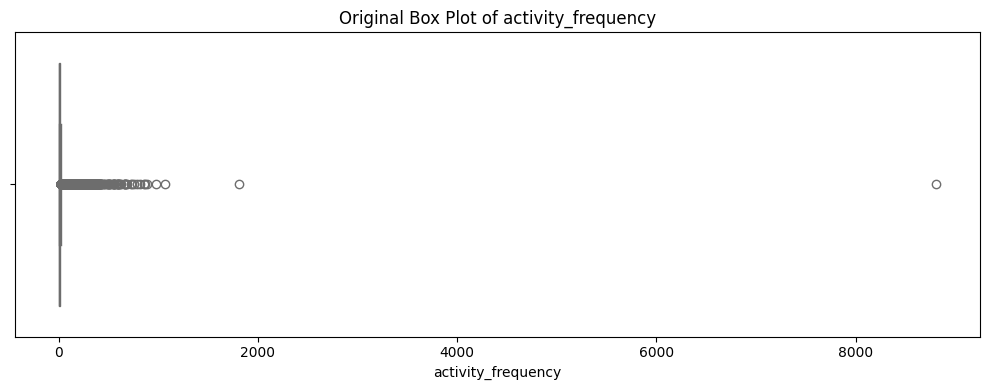

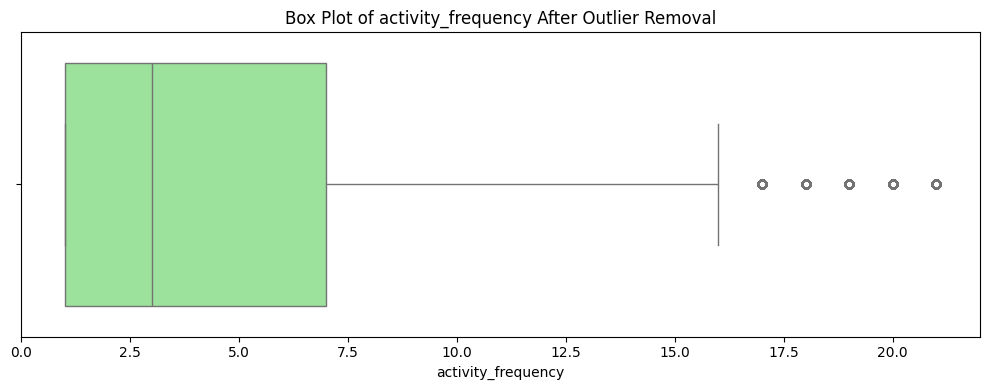

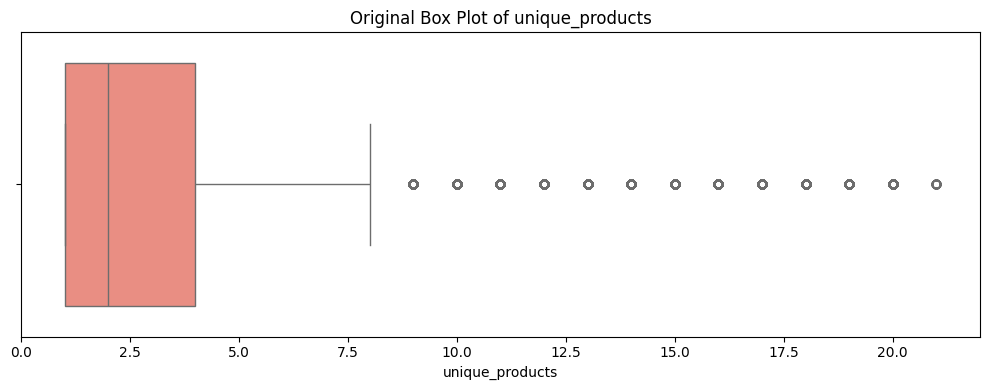

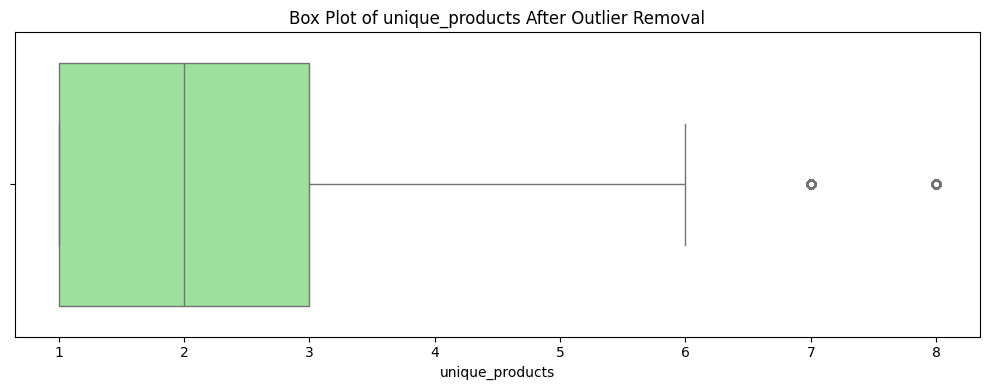

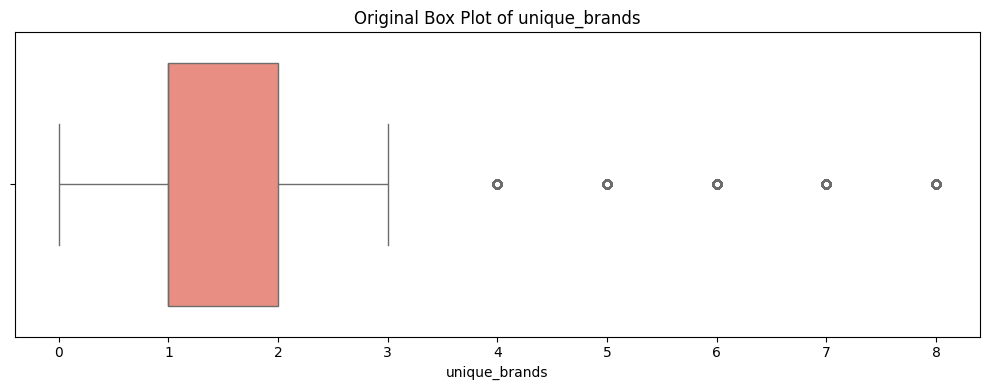

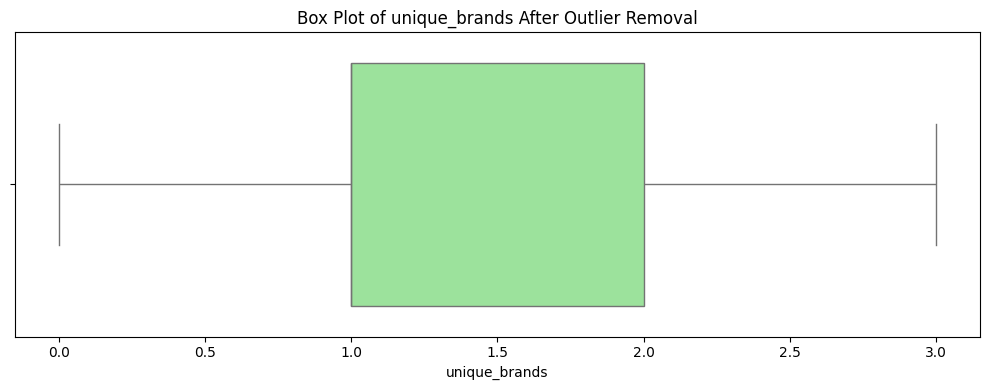

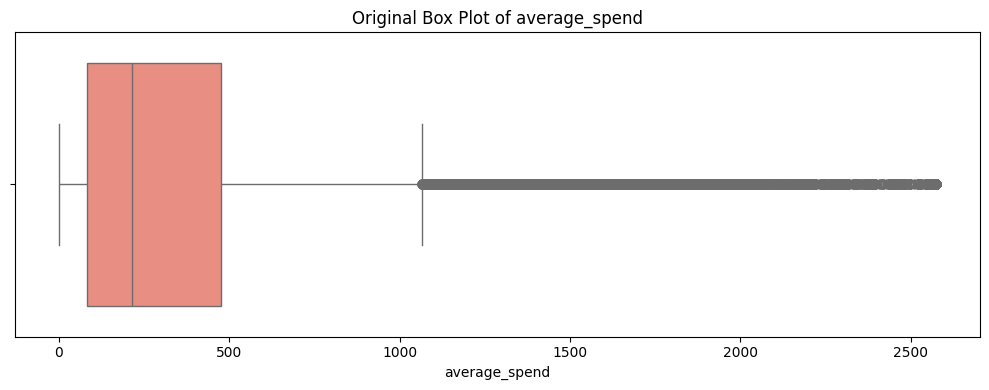

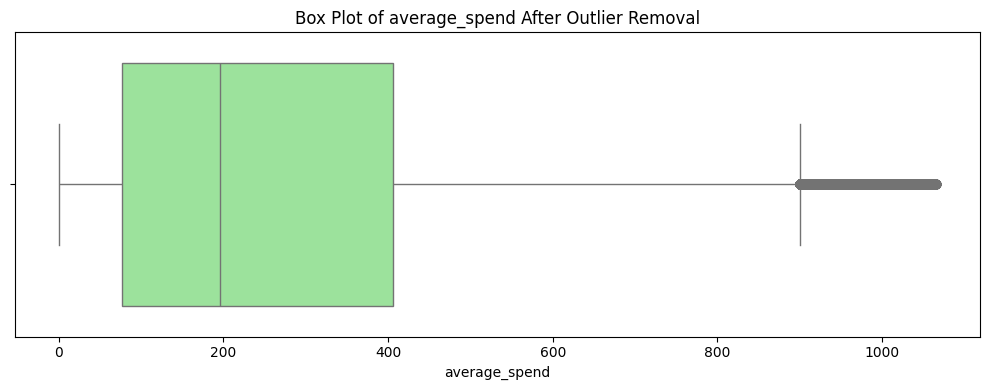

In [9]:
df_cleaned = process_boxplots_and_remove_outliers(user_features)    

In [10]:

features = ['activity_frequency', 'unique_products', 'unique_brands', 'average_spend']

scaler = StandardScaler()
scaled_data = scaler.fit_transform(df_cleaned[features])

In [11]:
scaled_data

array([[-0.7776118 , -0.73684836, -1.7575625 , -0.9481715 ],
       [-0.7776118 , -0.73684836, -1.7575625 ,  1.04837199],
       [-0.7776118 , -0.73684836, -0.42997795,  2.45980919],
       ...,
       [-0.7776118 , -0.73684836, -0.42997795, -0.33304875],
       [-0.49588775, -0.73684836, -0.42997795,  1.5910493 ],
       [-0.7776118 , -0.73684836, -0.42997795, -0.65983393]],
      shape=(438042, 4))

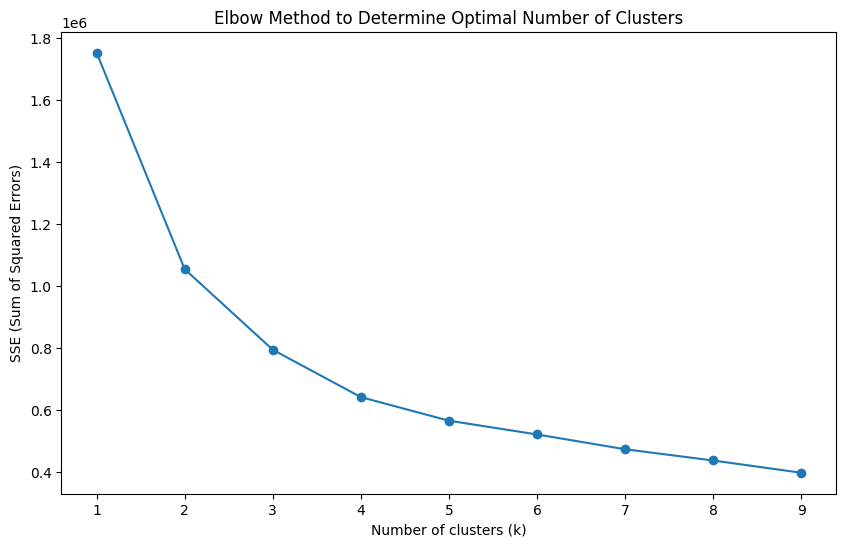

In [12]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Function to compute SSE for each number of clusters
sse = []
K_range = range(1, 10)  # Try cluster numbers from 1 to 10

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(scaled_data)
    sse.append(kmeans.inertia_)  # inertia_ is the total SSE

# Plot the Elbow graph
plt.figure(figsize=(10, 6))
plt.plot(K_range, sse, marker='o')
plt.xlabel('Number of clusters (k)')
plt.ylabel('SSE (Sum of Squared Errors)')
plt.title('Elbow Method to Determine Optimal Number of Clusters')
plt.show()


In [13]:
# Choose the optimal number of clusters, e.g., k = 4 based on the Elbow plot
optimal_k = 4

# Apply K-Means with the optimal number of clusters
kmeans = KMeans(n_clusters=optimal_k, random_state=42)
df_cleaned['cluster'] = kmeans.fit_predict(scaled_data)

# Display the clustered user features
df_cleaned


,user_id,activity_frequency,unique_products,unique_brands,average_spend,cluster
0,86517859,1,1,0,36.75,2
1,96847785,1,1,0,548.25,0
2,98232836,1,1,1,909.85,0
3,104655840,1,1,0,9.91,2
5,134184564,1,1,1,142.01,2
...,...,...,...,...,...,...
594946,636498836,2,1,1,687.28,0
594947,636498857,1,1,1,41.06,2
594949,636498871,1,1,1,194.34,2
594950,636498883,2,1,1,687.28,0


In [14]:
cluster_counts = df_cleaned['cluster'].value_counts()
cluster_counts

cluster
2    219977
1     91803
0     74084
3     52178
Name: count, dtype: int64

In [15]:
# Group the data by cluster
grouped = df_cleaned.groupby('cluster')

# Calculate descriptive statistics for each cluster
for cluster, group in grouped:
    print(f"\nCluster {cluster} - Behavioral Characteristics:")

    # Calculate behavioral metrics for each cluster
    unique_users = group['user_id'].nunique()
    avg_activity = group['activity_frequency'].mean()
    avg_spend = group['average_spend'].mean()
    avg_unique_products = group['unique_products'].mean()
    avg_unique_brands = group['unique_brands'].mean()

    # Print key characteristics of each cluster
    print(f"Number of users in the cluster: {unique_users}")
    print(f"Average activity frequency: {avg_activity:.2f}")
    print(f"Average unique products: {avg_unique_products:.2f}")
    print(f"Average spending: {avg_spend:.2f}")
    print(f"Average unique brands: {avg_unique_brands:.2f}")


Cluster 0 - Behavioral Characteristics:
Number of users in the cluster: 74084
Average activity frequency: 2.55
Average unique products: 1.66
Average spending: 712.48
Average unique brands: 1.12

Cluster 1 - Behavioral Characteristics:
Number of users in the cluster: 91803
Average activity frequency: 4.42
Average unique products: 3.01
Average spending: 205.11
Average unique brands: 2.19

Cluster 2 - Behavioral Characteristics:
Number of users in the cluster: 219977
Average activity frequency: 2.16
Average unique products: 1.27
Average spending: 155.86
Average unique brands: 0.86

Cluster 3 - Behavioral Characteristics:
Number of users in the cluster: 52178
Average activity frequency: 11.07
Average unique products: 5.36
Average spending: 318.26
Average unique brands: 2.05


In [16]:
from sklearn.metrics import davies_bouldin_score

score = davies_bouldin_score(scaled_data, df_cleaned['cluster'])
print(f"Davies-Bouldin Index: {score:.4f}")


Davies-Bouldin Index: 1.0839


In [17]:
from sklearn.metrics import calinski_harabasz_score

score = calinski_harabasz_score(scaled_data, df_cleaned['cluster'])
print(f"Calinski-Harabasz Score: {score:.2f}")


Calinski-Harabasz Score: 252909.13


In [29]:
from sklearn.metrics import silhouette_score
from sklearn.utils import resample

sample_size = 100000
X_sample, labels_sample = resample(
    scaled_data, df_cleaned['cluster'], 
    n_samples=sample_size, 
    random_state=42
)

score = silhouette_score(X_sample, labels_sample)
print(f"Silhouette Score (sampled): {score:.4f}")


Silhouette Score (sampled): 0.3967


In [19]:
# Group users by cluster and analyze behavioral patterns
grouped = df_cleaned.groupby('cluster')

for cluster_id, group in grouped:
    print(f"\nCluster {cluster_id} - Behavioral Profile")

    # Key metrics
    unique_users = group['user_id'].nunique()
    avg_activity = group['activity_frequency'].mean()
    avg_spend = group['average_spend'].mean()
    avg_unique_products = group['unique_products'].mean()
    avg_unique_brands = group['unique_brands'].mean()

    print(f"Number of users: {unique_users}")
    print(f"Average activity frequency: {avg_activity:.2f}")
    print(f"Average unique products interacted with: {avg_unique_products:.2f}")
    print(f"Average spending: ${avg_spend:.2f}")
    print(f"Average unique brands explored: {avg_unique_brands:.2f}")

    # Tailored interpretation and strategy
    print("Interpretation:")

    if cluster_id == 0:
        print("High-value but low-engagement users who make expensive purchases with focused product interest.")
        print("Suggested approach: Promote exclusive or high-end product deals and loyalty benefits to retain them.")
    
    elif cluster_id == 1:
        print("Low-to-mid spenders with moderate engagement and moderate product/brand variety.")
        print("Suggested approach: Offer bundle deals and personalized promotions to boost average order value.")
    
    elif cluster_id == 2:
        print("Large cluster of low-spend, low-engagement users with very limited product and brand interaction.")
        print("Suggested approach: Use welcome campaigns, targeted discounts, and retargeting to convert casual visitors into repeat customers.")
    
    elif cluster_id == 3:
        print("Engaged users with above-average activity and moderate spending across a variety of products and brands.")
        print("Suggested approach: Drive retention through personalized recommendations, loyalty rewards, and category-based campaigns.")

    # Additional insights
    if avg_unique_brands > 2:
        print("Additional Insight: Users explore a fair number of brands, suggesting openness to trying new options.")
    elif avg_unique_products < 2:
        print("Additional Insight: Focused shopping behavior—these users likely come with specific intent and buy only what they need.")
    elif avg_activity > 10:
        print("Additional Insight: High activity levels indicate active exploration or deal-seeking behavior.")

    print("-" * 60)



Cluster 0 - Behavioral Profile
Number of users: 74084
Average activity frequency: 2.55
Average unique products interacted with: 1.66
Average spending: $712.48
Average unique brands explored: 1.12
Interpretation:
High-value but low-engagement users who make expensive purchases with focused product interest.
Suggested approach: Promote exclusive or high-end product deals and loyalty benefits to retain them.
Additional Insight: Focused shopping behavior—these users likely come with specific intent and buy only what they need.
------------------------------------------------------------

Cluster 1 - Behavioral Profile
Number of users: 91803
Average activity frequency: 4.42
Average unique products interacted with: 3.01
Average spending: $205.11
Average unique brands explored: 2.19
Interpretation:
Low-to-mid spenders with moderate engagement and moderate product/brand variety.
Suggested approach: Offer bundle deals and personalized promotions to boost average order value.
Additional Insight

Phase -2 

In [20]:
X = df_cleaned

In [24]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam
from sklearn.preprocessing import StandardScaler
import numpy as np

# X = your standardized input features (scaled_data from Phase 1)
input_dim = X.shape[1]

# Define encoder
input_layer = Input(shape=(input_dim,))
encoder = Dense(64, activation='relu')(input_layer)
encoder = Dense(32, activation='relu')(encoder)
latent = Dense(10, activation='relu')(encoder)  # Try with 5 or 20 later

# Define decoder
decoder = Dense(32, activation='relu')(latent)
decoder = Dense(64, activation='relu')(decoder)
output_layer = Dense(input_dim, activation='linear')(decoder)

# Compile model
autoencoder = Model(inputs=input_layer, outputs=output_layer)
autoencoder.compile(optimizer=Adam(), loss='mse')

# Train the model
autoencoder.fit(X, X, epochs=50, batch_size=256, validation_split=0.1, verbose=1)


Epoch 1/50
1540/1540 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - loss: 4614189666533376.0000 - val_loss: 1239758.6250
Epoch 2/50
1540/1540 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 1017251072.0000 - val_loss: 15751.1533
Epoch 3/50
1540/1540 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - loss: 1999850240.0000 - val_loss: 95309128.0000
Epoch 4/50
1540/1540 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 4240262912.0000 - val_loss: 22280065024.0000
Epoch 5/50
1540/1540 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 26847203328.0000 - val_loss: 453144256.0000
Epoch 6/50
1540/1540 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 121773023232.0000 - val_loss: 34510278656.0000
Epoch 7/50
1540/1540 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - loss: 99945971712.0000 - val_loss: 20275034.0000
Epoch 8/50
1540/1540 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - loss: 123814985728.0000 - val_loss: 12149706.0000
Epoch 9/50
1540/1540 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - loss: 106677436416.0000 - val_loss: 286164549632.0000
Epoch 10/50
1540/1540 ━━━━━━━━━━━━━━━━━━━━ 

2. Extract Latent Features


In [25]:
encoder_model = Model(inputs=input_layer, outputs=latent)
X_latent = encoder_model.predict(X)


13689/13689 ━━━━━━━━━━━━━━━━━━━━ 21s 2ms/step


 3. Apply K-Means on Latent Features

In [26]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=4, random_state=42)
clusters = kmeans.fit_predict(X_latent)


Evaluate Cluster Quality

In [28]:
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

print("Silhouette Score:", silhouette_score(X_latent, clusters))
print("Calinski-Harabasz Index:", calinski_harabasz_score(X_latent, clusters))
print("Davies-Bouldin Index:", davies_bouldin_score(X_latent, clusters))


Silhouette Score: 0.6708789
Calinski-Harabasz Index: 3036752.0
Davies-Bouldin Index: 0.45289143581864943


5. Visualize with t-SNE

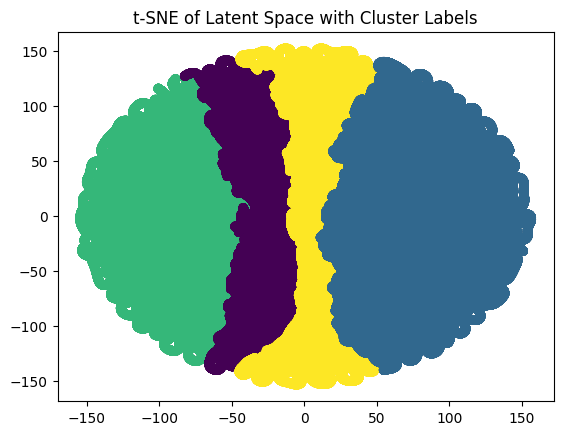

In [30]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

X_2d = TSNE(n_components=2, random_state=42).fit_transform(X_latent)
plt.scatter(X_2d[:,0], X_2d[:,1], c=clusters, cmap='viridis')
plt.title("t-SNE of Latent Space with Cluster Labels")
plt.show()
